# 03 — Phân tích dữ liệu và liên hệ với dự đoán điểm review

**Mục tiêu chính:** tìm hiểu giá, metadata và nội dung review liên hệ với điểm như thế nào. Mô hình Ridge kết hợp là phần dự đoán bổ trợ, đã huấn luyện và đánh giá test ngày 13/11/2026.

Mọi phân tích chi tiết và thống kê mới dùng train. Audit missing dùng cleaned; holdout chỉ đọc review để audit trùng. Không fit mô hình, đổi split hoặc tuning trong notebook. Điểm thuộc người đánh giá, không phải phép đo chất lượng khách quan.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.create_eda_plots import run_eda, metadata_groups
from src.reporting import sha256
OUT = ROOT / 'outputs/eda'
tables = run_eda(OUT)
def show_figure(name):
    display(Image(filename=str(OUT / 'figures' / f'{name}.png')))


## 1. Dữ liệu nào được phân tích?
**Câu hỏi:** cleaned và mẫu có giá khác nhau ra sao? **Cách đọc:** số mẫu và missing là hai bảng audit, không phải dữ liệu đã điền giá. **Hàm ý:** giữ giá thiếu trong nguồn, mô hình hiện tại dùng mẫu có giá quan sát. **Giới hạn:** mẫu này có thể khác nhóm thiếu giá.

,sample,rows
0,cleaned,119988
1,observed_price,111593
2,missing_price,8395
3,train,78106


,column,dtype,missing,missing_pct
0,country,str,0,0.000000
1,description,str,0,0.000000
2,designation,str,0,0.000000
3,points,int64,0,0.000000
4,price,float64,8395,6.996533
5,province,str,0,0.000000
6,region_1,str,0,0.000000
7,region_2,str,0,0.000000
8,taster_name,str,0,0.000000
9,taster_twitter_handle,str,0,0.000000


,count,mean,std,min,25%,50%,75%,max
points,78106.0,88.415973,3.103525,80.000000,86.000000,88.000000,91.0000,100.000000
price,78106.0,35.656032,41.364469,4.000000,17.000000,25.000000,42.0000,2500.000000
log_price,78106.0,3.359111,0.637869,1.609438,2.890372,3.258097,3.7612,7.824446
vintage_year,75426.0,2010.641622,3.631384,1980.000000,2009.000000,2011.000000,2013.0000,2017.000000


**Kết quả train:** điểm trung bình 88.42, độ lệch chuẩn 3.10; phạm vi 80–100. Phân bố tập trung khiến baseline trung bình là mốc đối chiếu cần thiết.

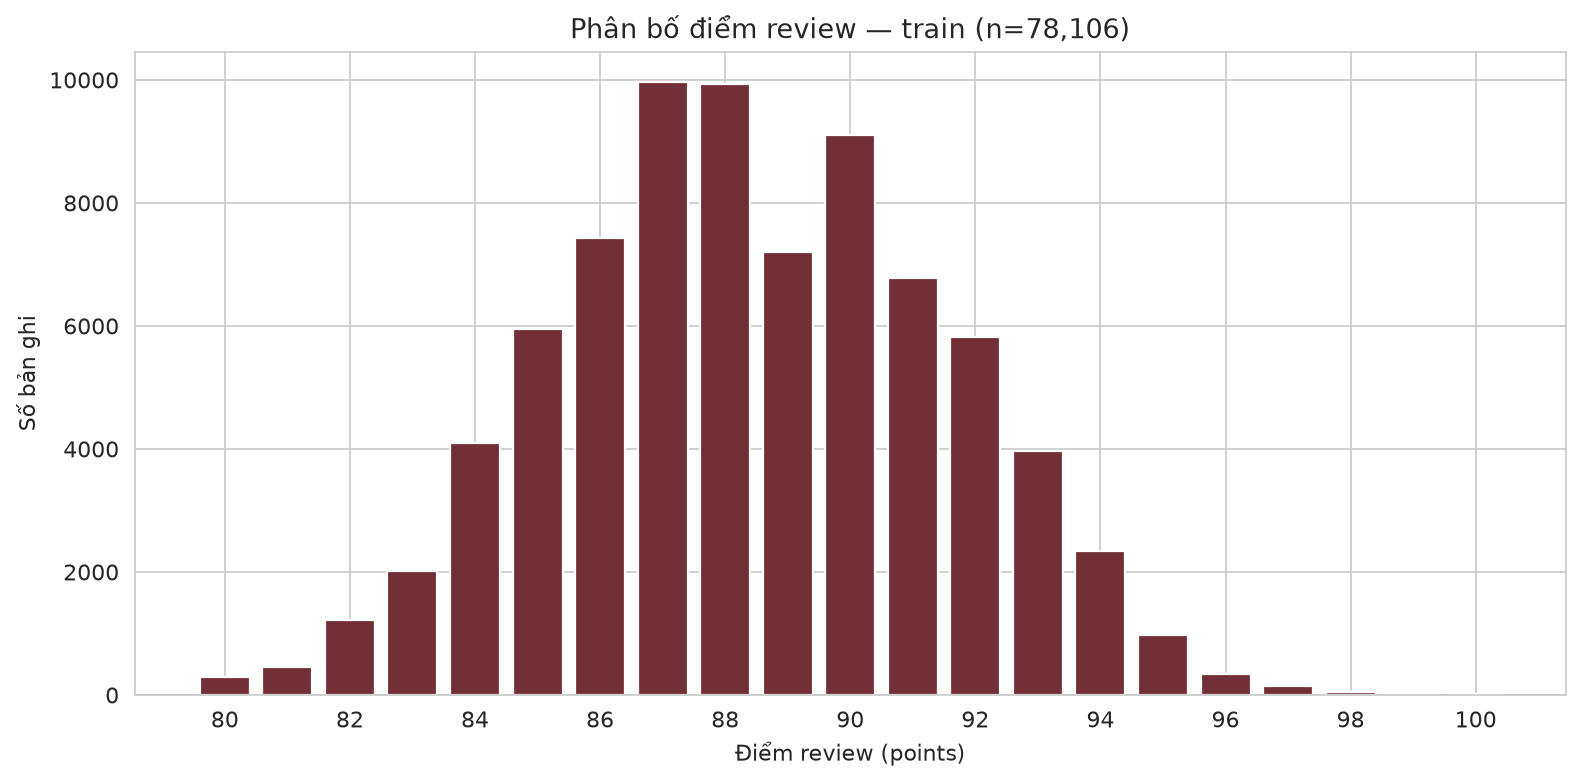

In [2]:
display(tables['sample_counts'])
display(tables['audit_missing'])
s = tables['numeric_summary']
display(s)
display(Markdown(f"**Kết quả train:** điểm trung bình {s.loc['points','mean']:.2f}, độ lệch chuẩn {s.loc['points','std']:.2f}; phạm vi {s.loc['points','min']:.0f}–{s.loc['points','max']:.0f}. Phân bố tập trung khiến baseline trung bình là mốc đối chiếu cần thiết."))
show_figure('01_points_distribution')

## 2. Giá liên hệ với điểm như thế nào?
**Cách đọc:** so histogram giá gốc/log, scatter trục giá log và điểm trung vị theo bốn khoảng giá. Khoảng giá tính trên train, không cắt đuôi cao. **Quyết định:** giữ giá cao hợp lệ; dùng log để biểu diễn giá lệch phải. **Giới hạn:** liên hệ không chứng minh nhân quả, chưa có đối chứng về lợi ích dự đoán của log.

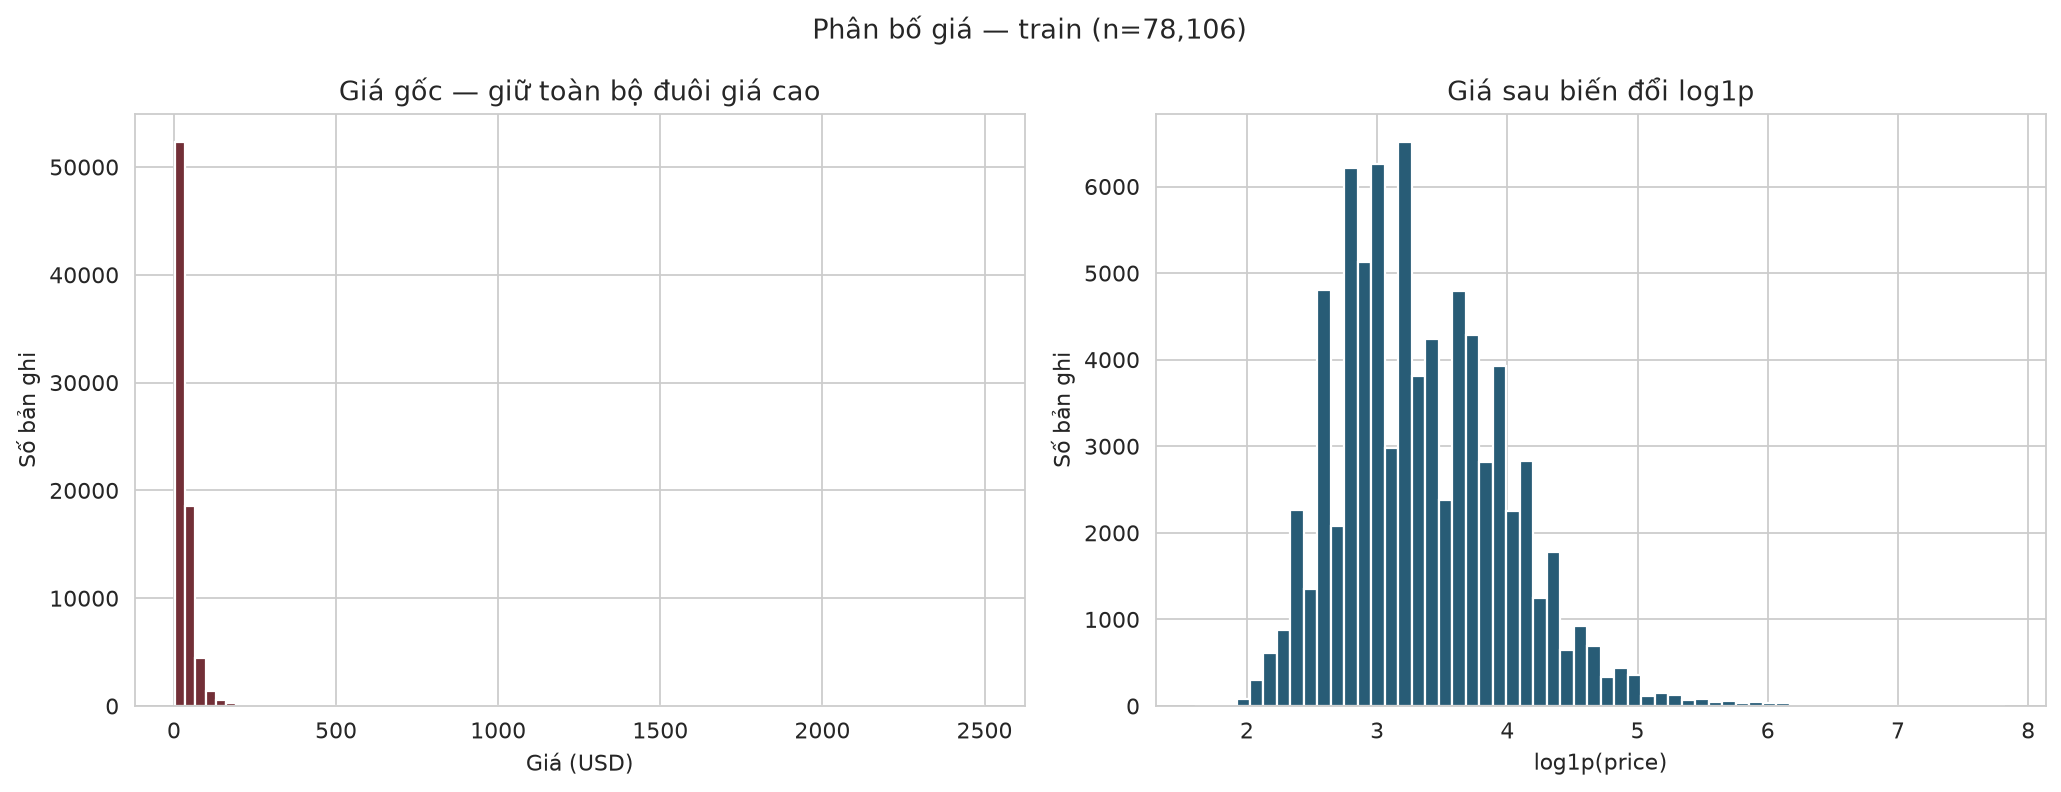

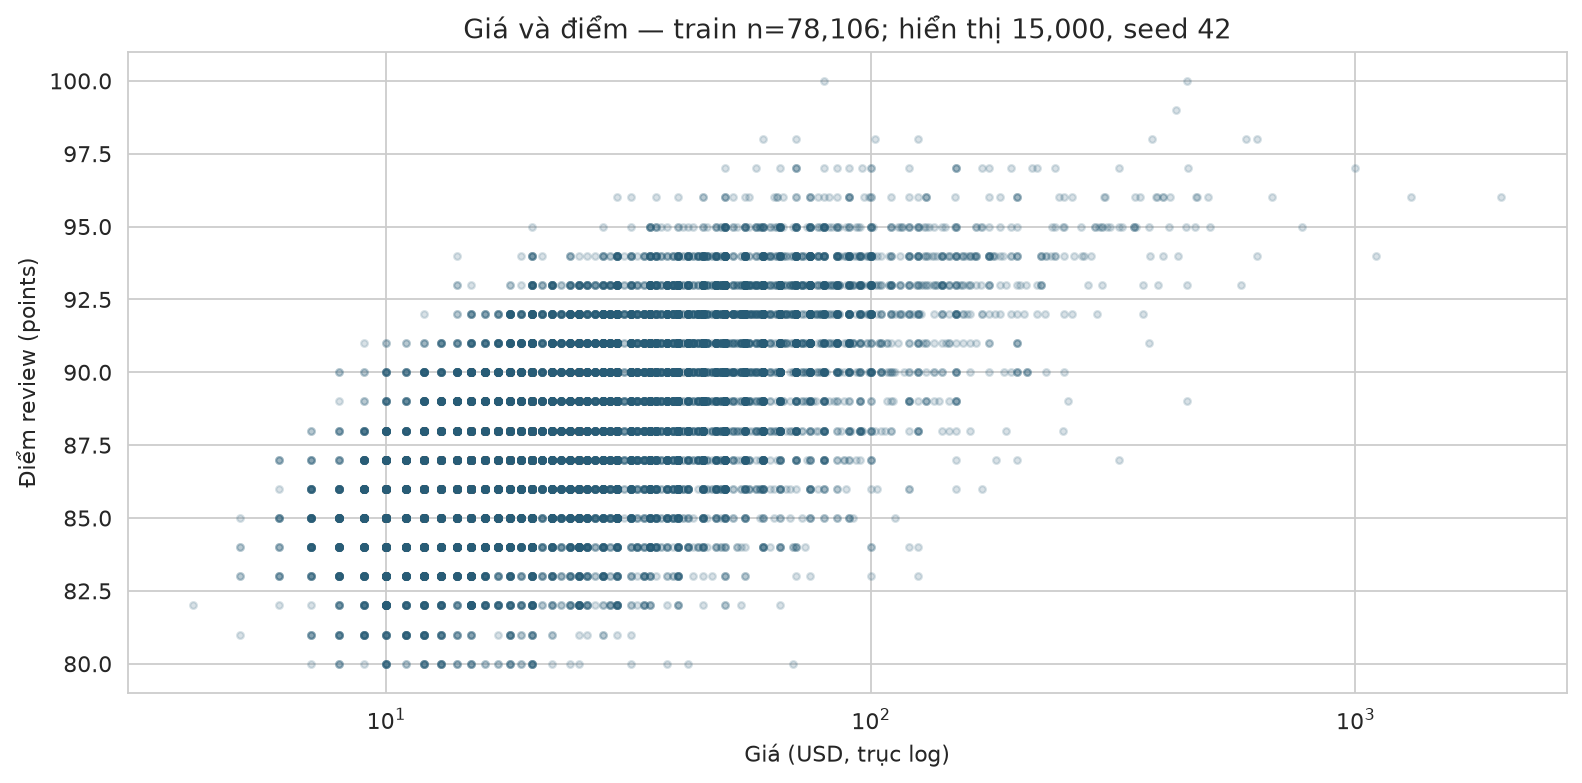

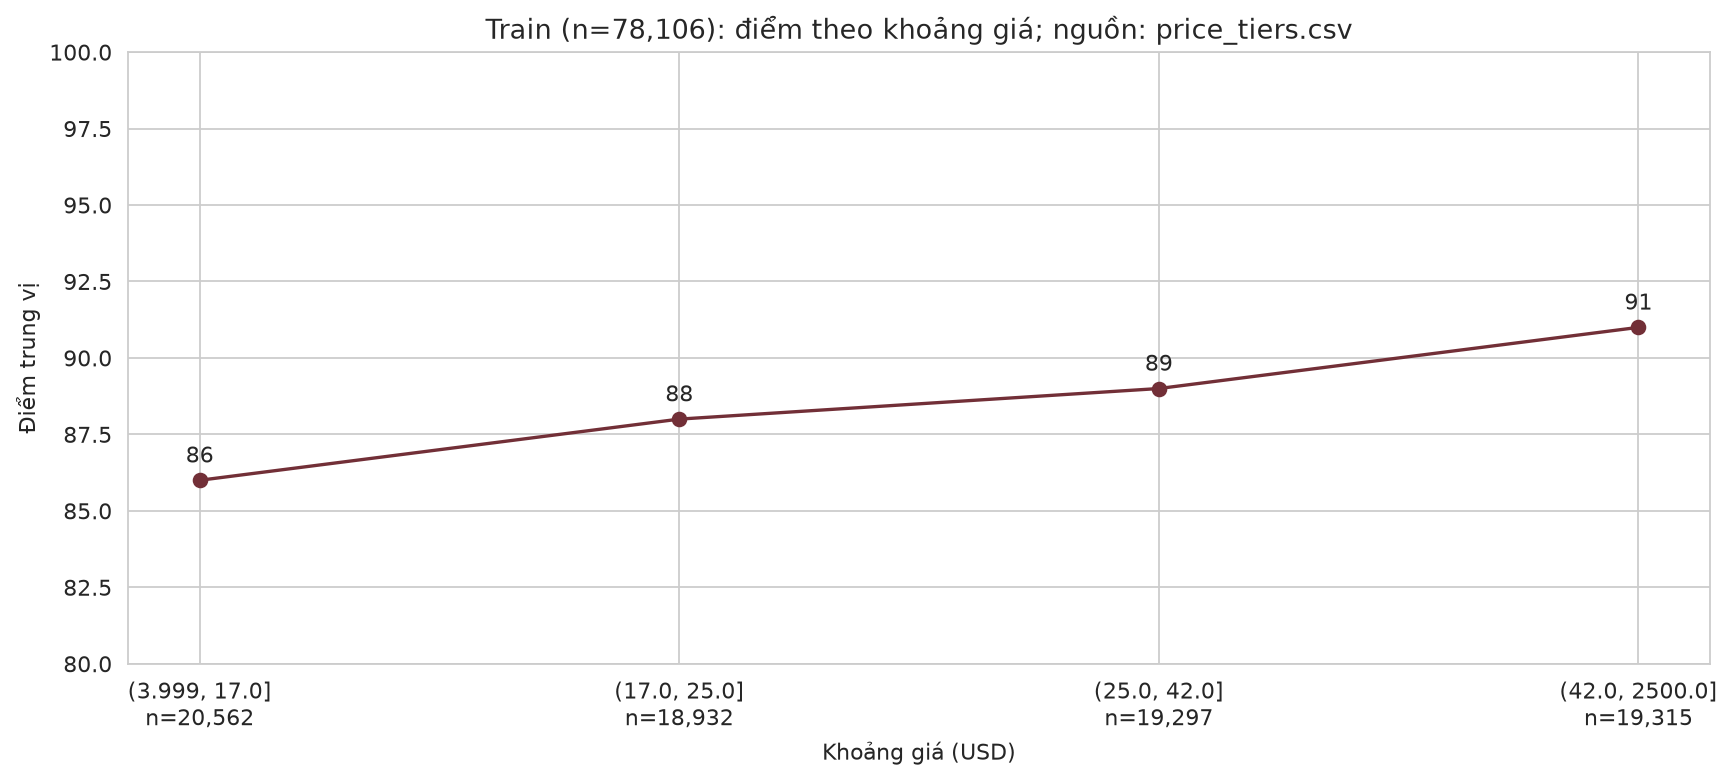

,rows,price_median,points_median,points_mean
price_interval_usd,,,,
"(3.999, 17.0]",20562,13.0,86.0,86.081072
"(17.0, 25.0]",18932,21.0,88.0,87.729823
"(25.0, 42.0]",19297,33.0,89.0,88.975177
"(42.0, 2500.0]",19315,60.0,91.0,91.015480


**Kết quả:** giá trung vị 25 USD, trung bình 35.66 USD; điểm trung vị theo khoảng giá: 86 → 88 → 89 → 91.

In [3]:
show_figure('02_price_distribution')
show_figure('03_price_points')
show_figure('08_price_tier_points')
display(tables['price_tiers'])
medians = ' → '.join(f'{x:g}' for x in tables['price_tiers'].points_median)
display(Markdown(f"**Kết quả:** giá trung vị {s.loc['price','50%']:.0f} USD, trung bình {s.loc['price','mean']:.2f} USD; điểm trung vị theo khoảng giá: {medians}."))

## 3. Quốc gia, vùng và giống nho khác nhau ra sao?
**Cách đọc:** so quy mô, giá và boxplot điểm trên cùng tối đa 10 nhóm đông nhất có ít nhất 100 dòng; loại placeholder. **Hàm ý:** khác biệt điểm cần đặt trong bối cảnh giá và cơ cấu mẫu. **Giới hạn:** chưa kiểm định khác biệt nhóm, chưa điều chỉnh người chấm hoặc tuyển chọn; không xếp hạng chất lượng.

### country

,rows,missing_price,price_median,points_mean,points_median,points_q25,points_q75
country,,,,,,,
US,35165,0,30.0,88.560273,88.0,86.0,91.0
France,11397,0,25.0,88.762394,89.0,86.0,91.0
Italy,10755,0,28.0,88.639888,88.0,87.0,90.0
Spain,4280,0,18.0,87.235280,87.0,85.0,89.0
Portugal,3150,0,17.0,88.382222,88.0,86.0,91.0
Chile,2958,0,15.0,86.454023,86.0,85.0,88.0
Argentina,2482,0,17.0,86.650282,87.0,84.0,89.0
Austria,1754,0,25.0,90.259407,90.0,89.0,92.0
Australia,1515,0,21.0,88.570957,89.0,86.0,91.0


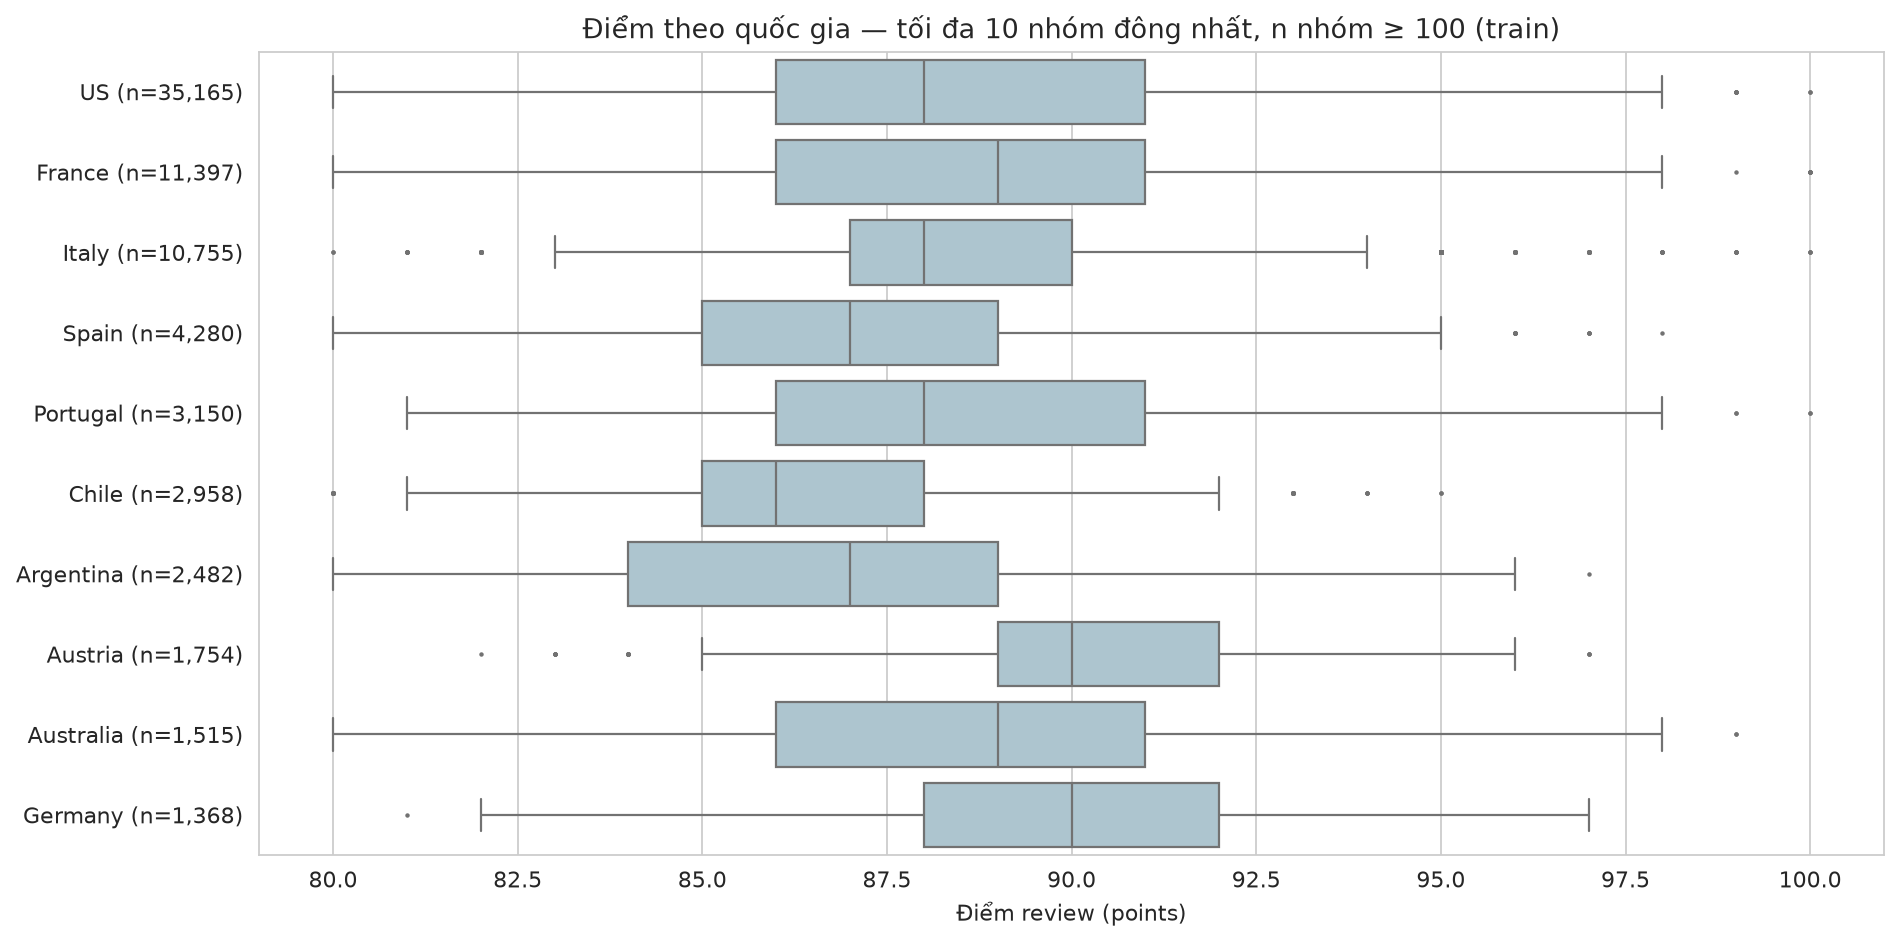

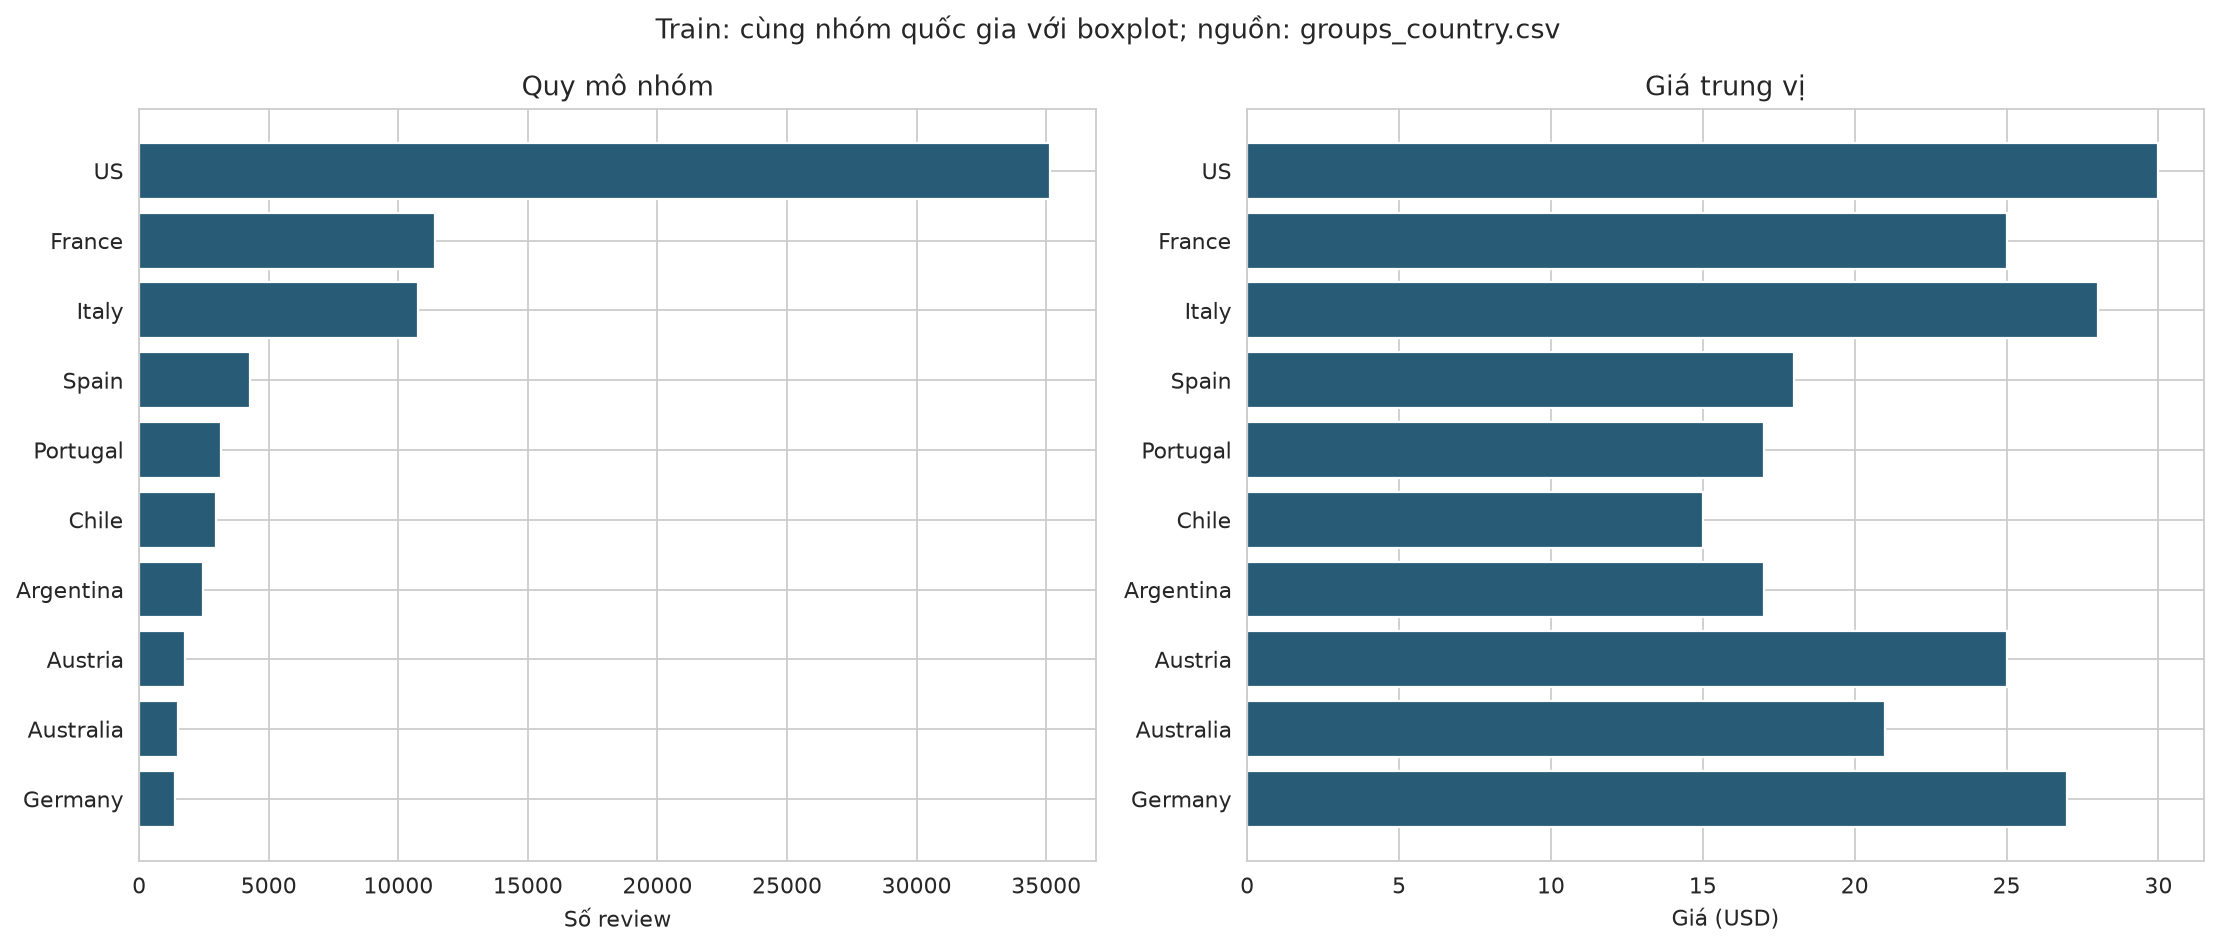

**Kết quả:** nhóm đông nhất US, n=35,165; chênh trung bình cao nhất–thấp nhất 3.81 điểm. Hai nhóm đó có Q1–Q3 [85, 88] và [89, 92]; đọc cả phần chồng lấn thay vì chỉ trung bình.

### province

,rows,missing_price,price_median,points_mean,points_median,points_q25,points_q75
province,,,,,,,
California,23424,0,32.0,88.624744,89.0,86.0,91.0
Washington,5560,0,29.0,88.978777,89.0,87.0,91.0
Oregon,3418,0,30.0,89.059977,89.0,87.0,91.0
Tuscany,3250,0,35.0,89.240923,89.0,87.0,91.0
Bordeaux,2569,0,20.0,87.998054,88.0,86.0,90.0
Northern Spain,2476,0,19.0,87.359451,87.0,85.0,90.0
Mendoza Province,2136,0,17.0,86.769195,87.0,84.0,89.0
Burgundy,2022,0,43.0,89.696835,90.0,87.0,92.0
Piedmont,1984,0,49.0,89.612903,90.0,87.0,92.0


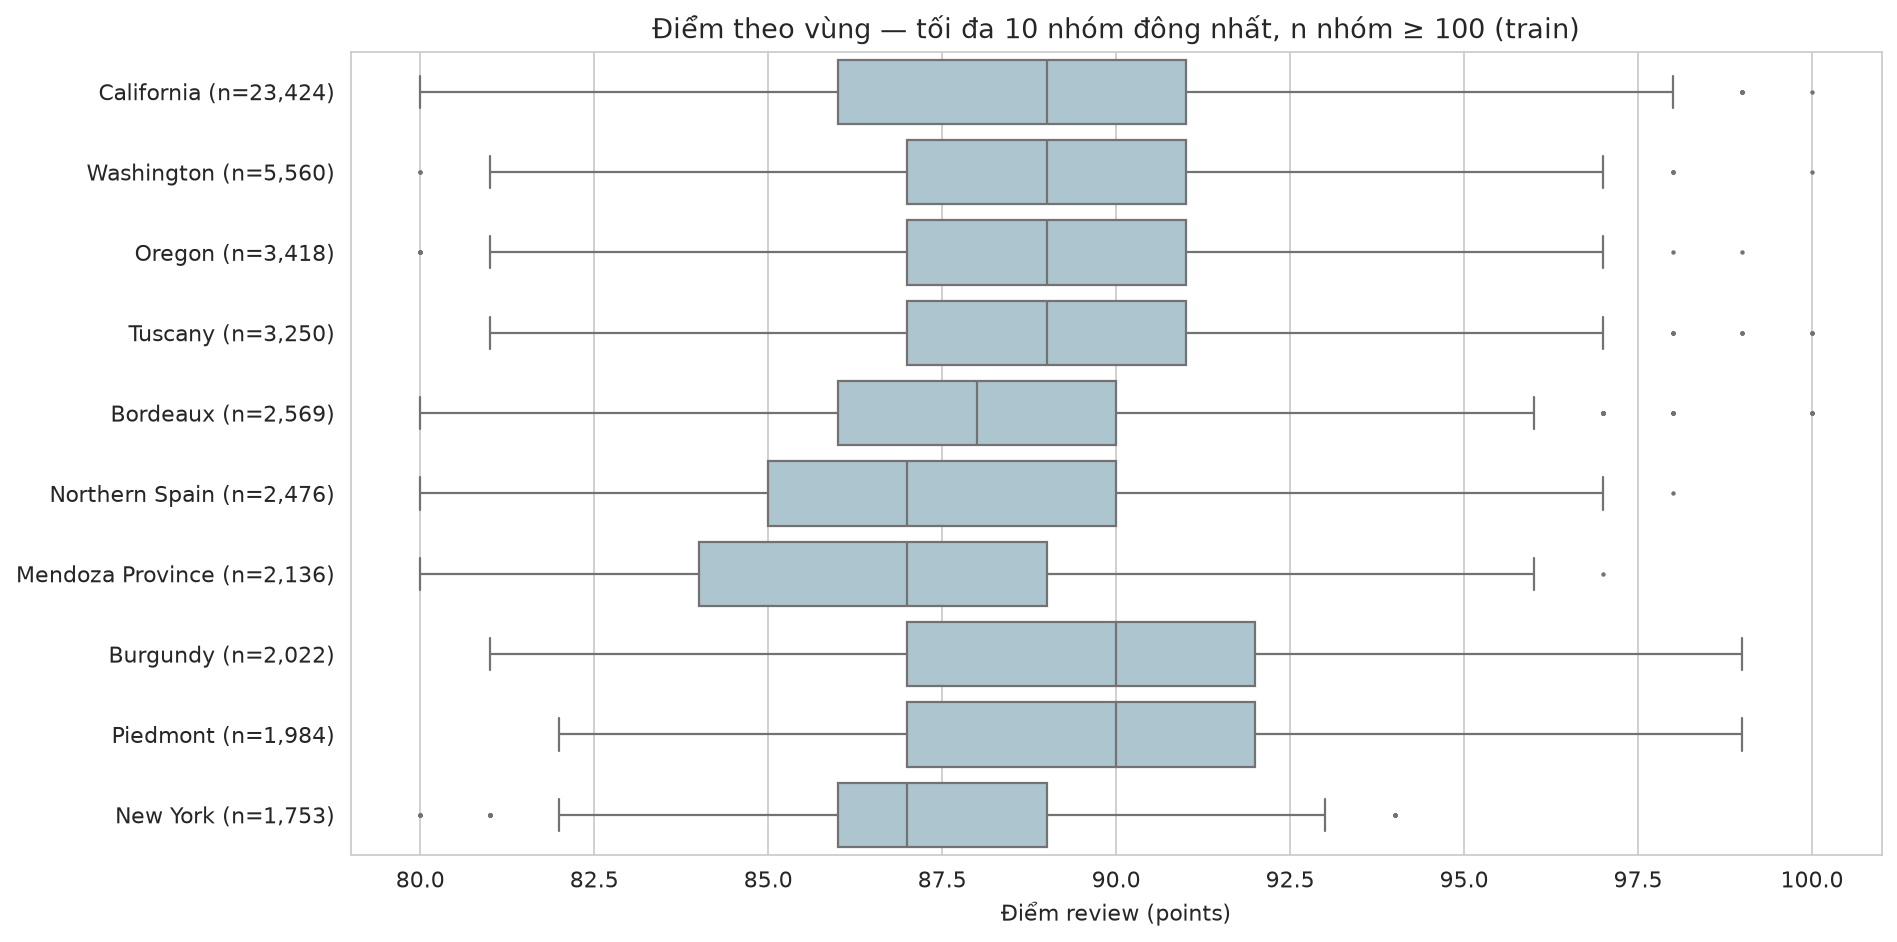

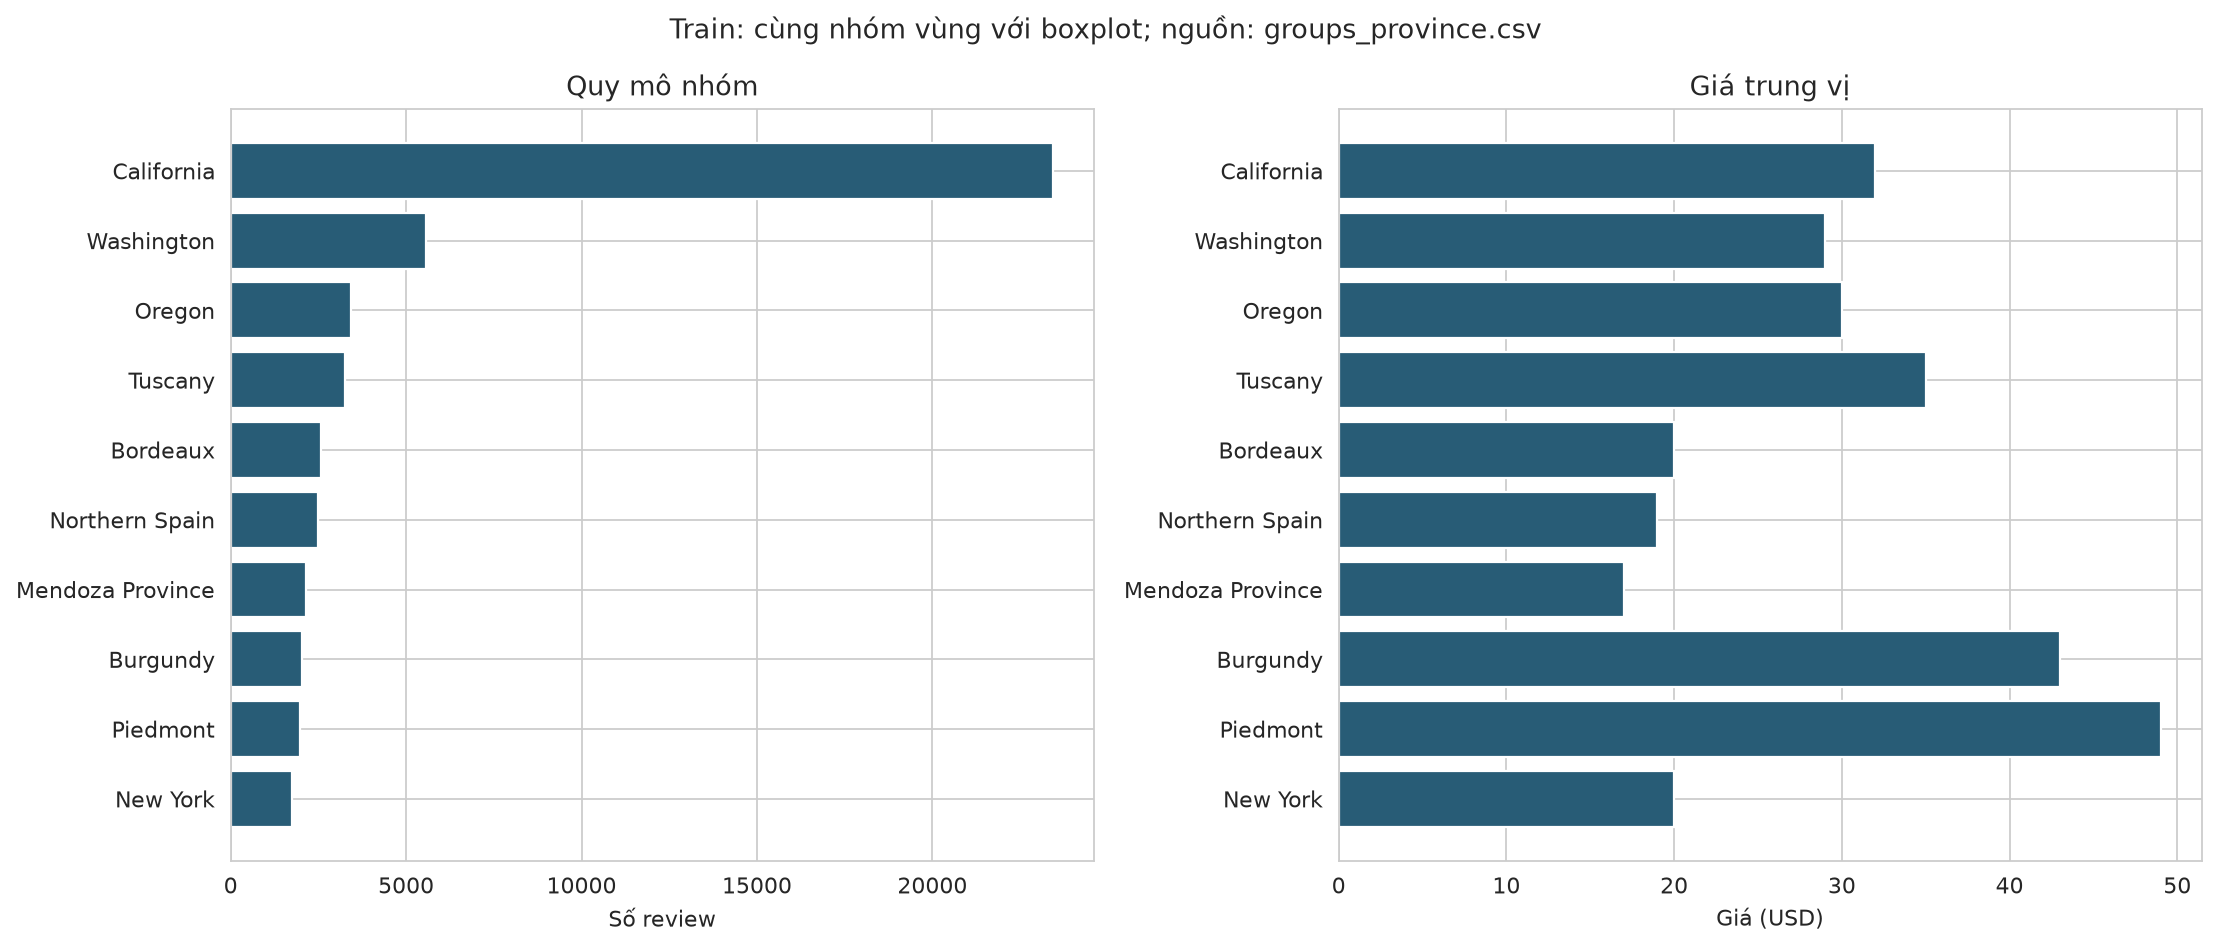

**Kết quả:** nhóm đông nhất California, n=23,424; chênh trung bình cao nhất–thấp nhất 2.93 điểm. Hai nhóm đó có Q1–Q3 [84, 89] và [87, 92]; đọc cả phần chồng lấn thay vì chỉ trung bình.

### variety

,rows,missing_price,price_median,points_mean,points_median,points_q25,points_q75
variety,,,,,,,
Pinot Noir,8254,0,42.0,89.455052,90.0,87.0,92.0
Chardonnay,7196,0,26.0,88.303224,88.0,86.0,91.0
Cabernet Sauvignon,6128,0,36.0,88.602154,88.0,86.0,91.0
Red Blend,5452,0,28.0,88.370323,88.0,87.0,90.0
Bordeaux-style Red Blend,3436,0,30.0,88.829453,89.0,87.0,91.0
Riesling,3224,0,22.0,89.480459,90.0,87.0,92.0
Sauvignon Blanc,3103,0,18.0,87.321947,87.0,85.0,89.0
Syrah,2637,0,35.0,89.253697,90.0,87.0,92.0
Rosé,2072,0,16.0,86.788127,87.0,85.0,89.0


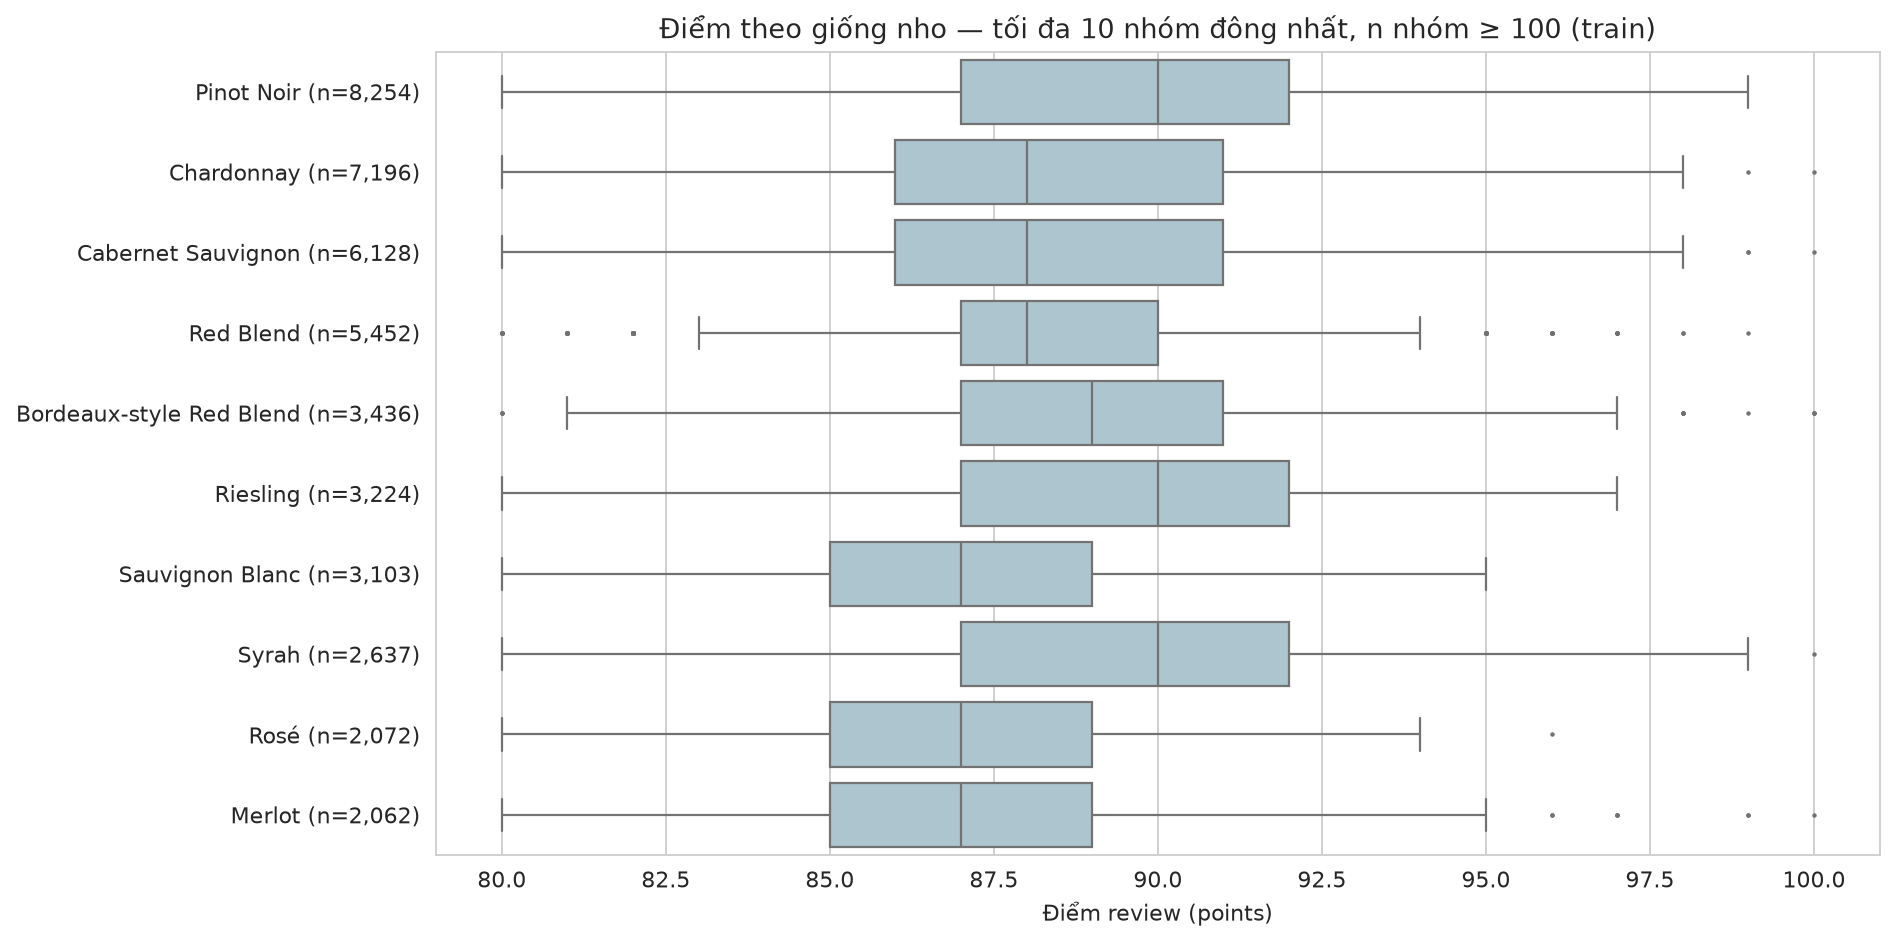

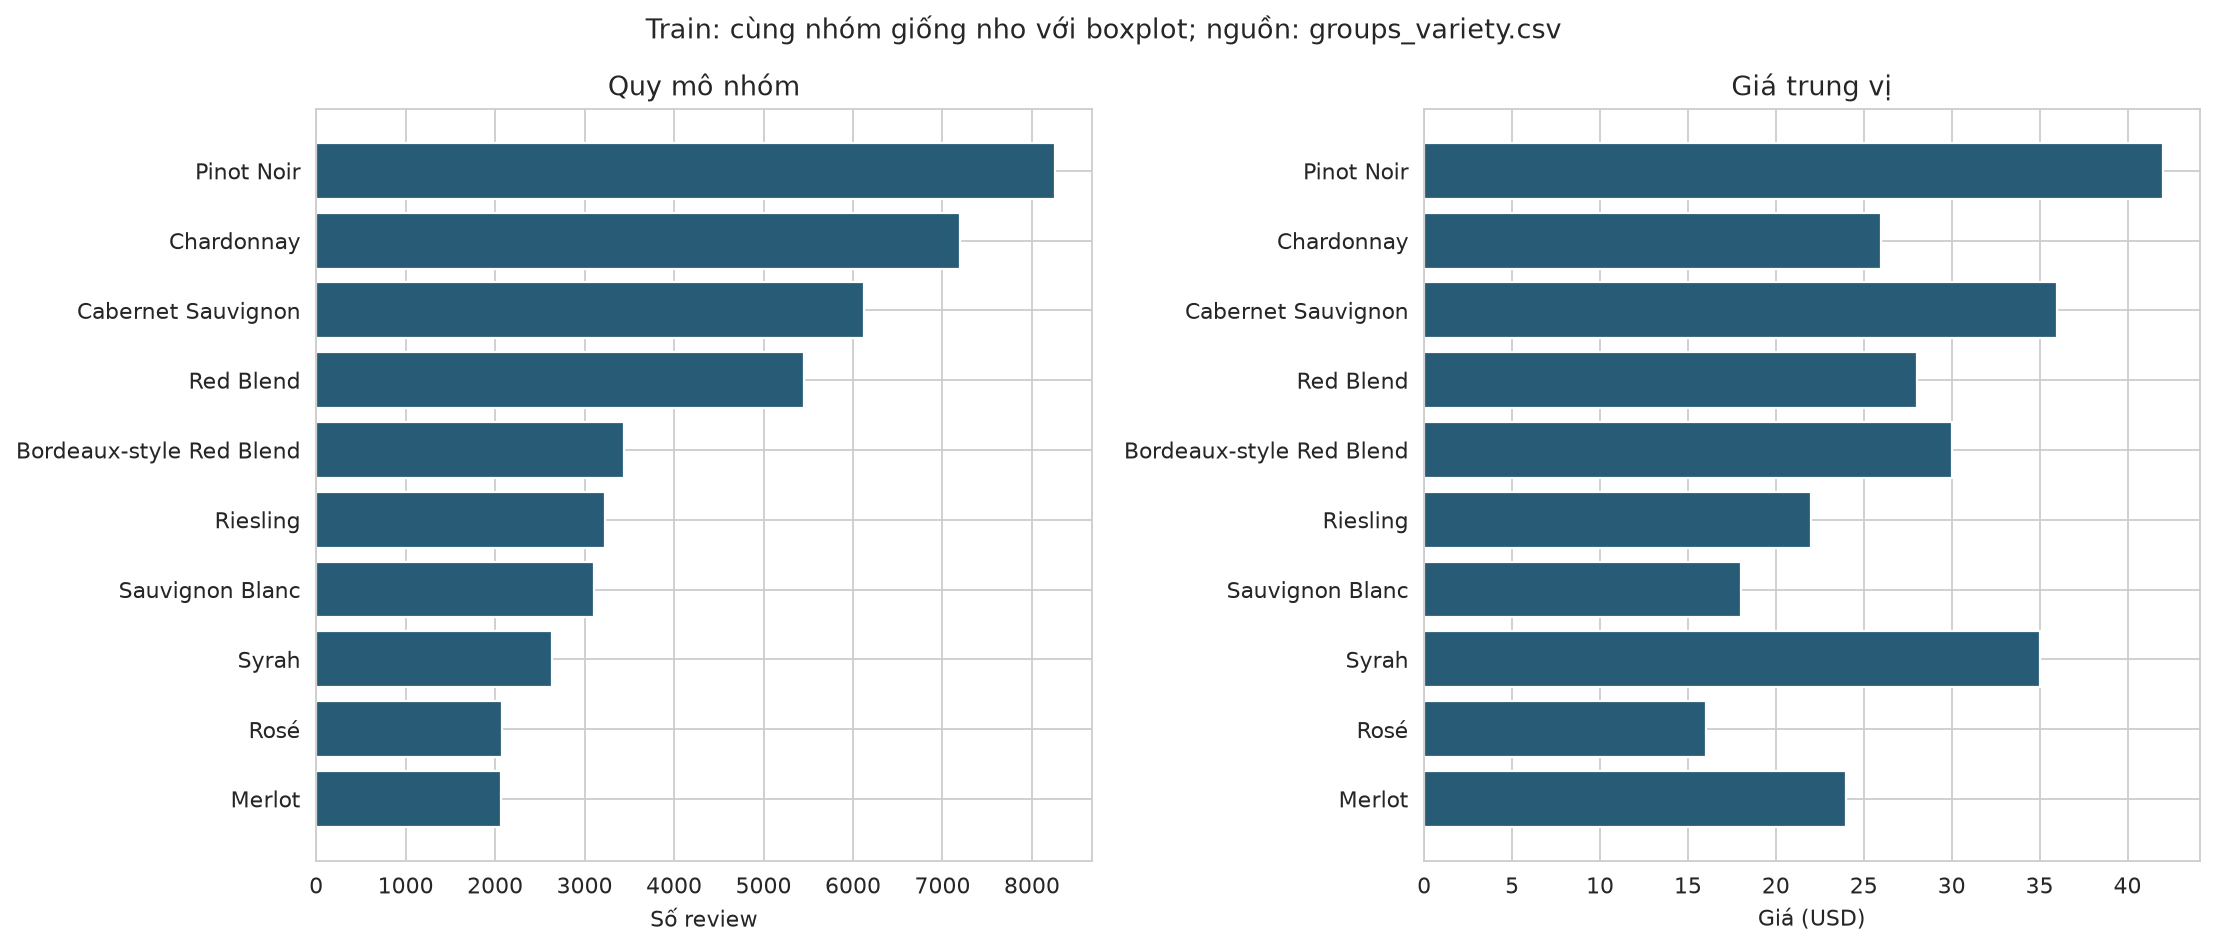

**Kết quả:** nhóm đông nhất Pinot Noir, n=8,254; chênh trung bình cao nhất–thấp nhất 2.69 điểm. Hai nhóm đó có Q1–Q3 [85, 89] và [87, 92]; đọc cả phần chồng lấn thay vì chỉ trung bình.

In [4]:
for column in ['country', 'province', 'variety']:
    groups = tables[f'groups_{column}']
    selected = groups.loc[metadata_groups(pd.read_csv(ROOT / 'data/processed/splits/train.csv', usecols=[column]), column)]
    display(Markdown(f'### {column}'))
    display(selected)
    show_figure(f'04_{column}_points')
    show_figure(f'07_{column}_context')
    first = selected.iloc[0]
    ordered = selected.sort_values('points_mean')
    low, high = ordered.iloc[0], ordered.iloc[-1]
    display(Markdown(f"**Kết quả:** nhóm đông nhất {selected.index[0]}, n={int(first.rows):,}; chênh trung bình cao nhất–thấp nhất {selected.points_mean.max()-selected.points_mean.min():.2f} điểm. Hai nhóm đó có Q1–Q3 [{low.points_q25:g}, {low.points_q75:g}] và [{high.points_q25:g}, {high.points_q75:g}]; đọc cả phần chồng lấn thay vì chỉ trung bình."))

## 4. Review có đặc điểm gì về độ dài và từ vựng?
**Cách đọc:** histogram độ dài, boxplot theo điểm; bảng gốc giữ stopword, bảng bổ sung lọc stopword scikit-learn nhưng giữ no/not/nor/never/without. Top 20 unigram bổ sung phải có mặt trong ≥100 review, sắp document frequency giảm rồi từ tăng. **Quyết định:** không loại review ngắn; không đổi TF-IDF. **Giới hạn:** không phải sentiment hoặc mức ảnh hưởng; viết dài không được chứng minh làm điểm cao.

,rows,empty_reviews,under_10_words,flagged_non_informative,median_words,min_words,max_words
0,78106,0,29,29,40.0,3,135


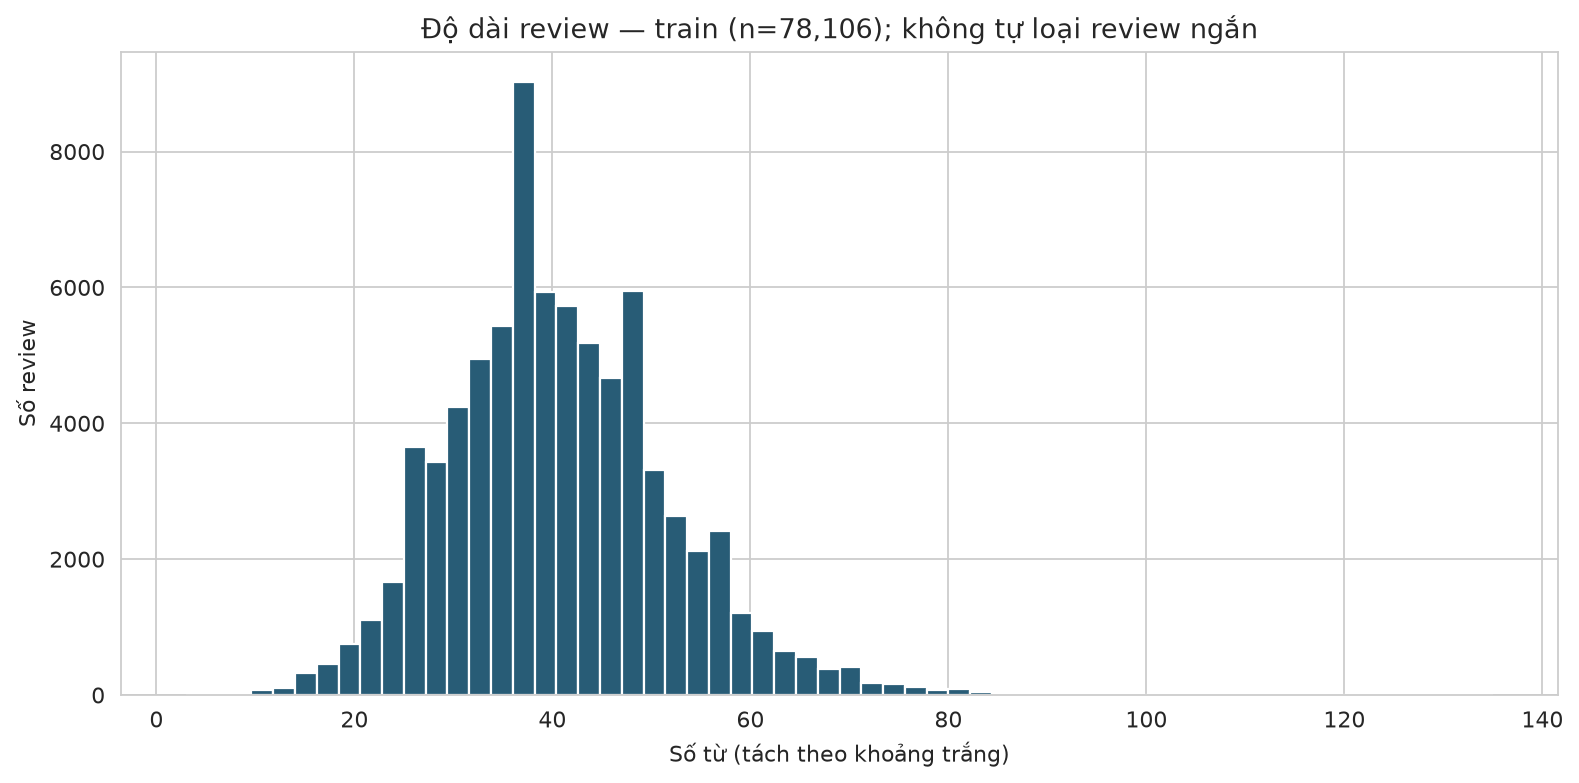

,points_band,rows,median_words
0,≤85,14040,32.0
1,86–89,34519,38.0
2,90–94,28008,45.0
3,≥95,1539,56.0


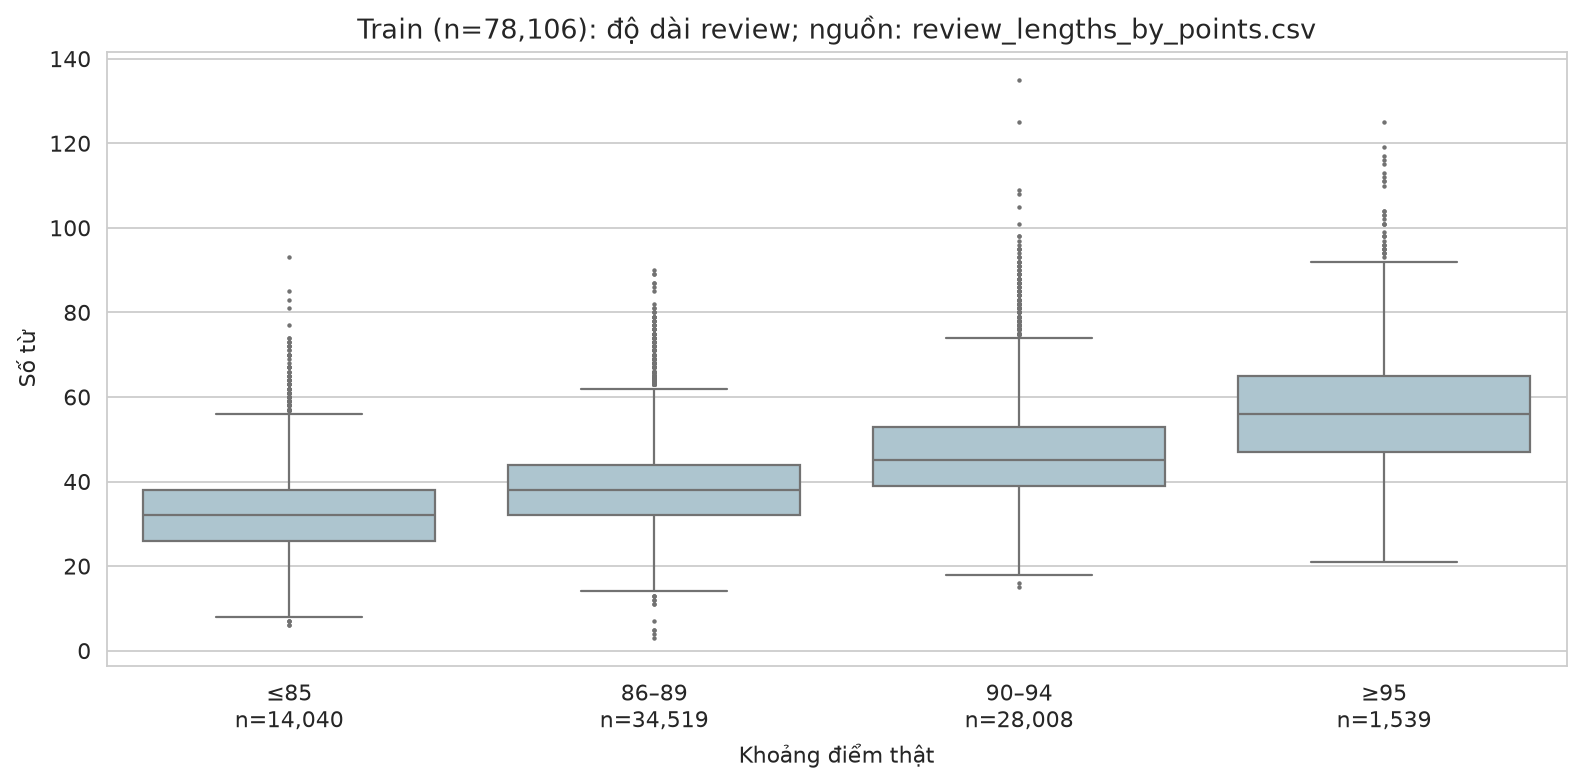

,term,occurrences,documents
0,and,212131,76661
1,the,133090,63004
2,of,104915,60091
3,with,73011,51486
4,this,68666,59263
5,is,57293,41695
6,it,52267,39262
7,wine,46615,37783
8,flavors,38951,37020
9,in,38594,29912


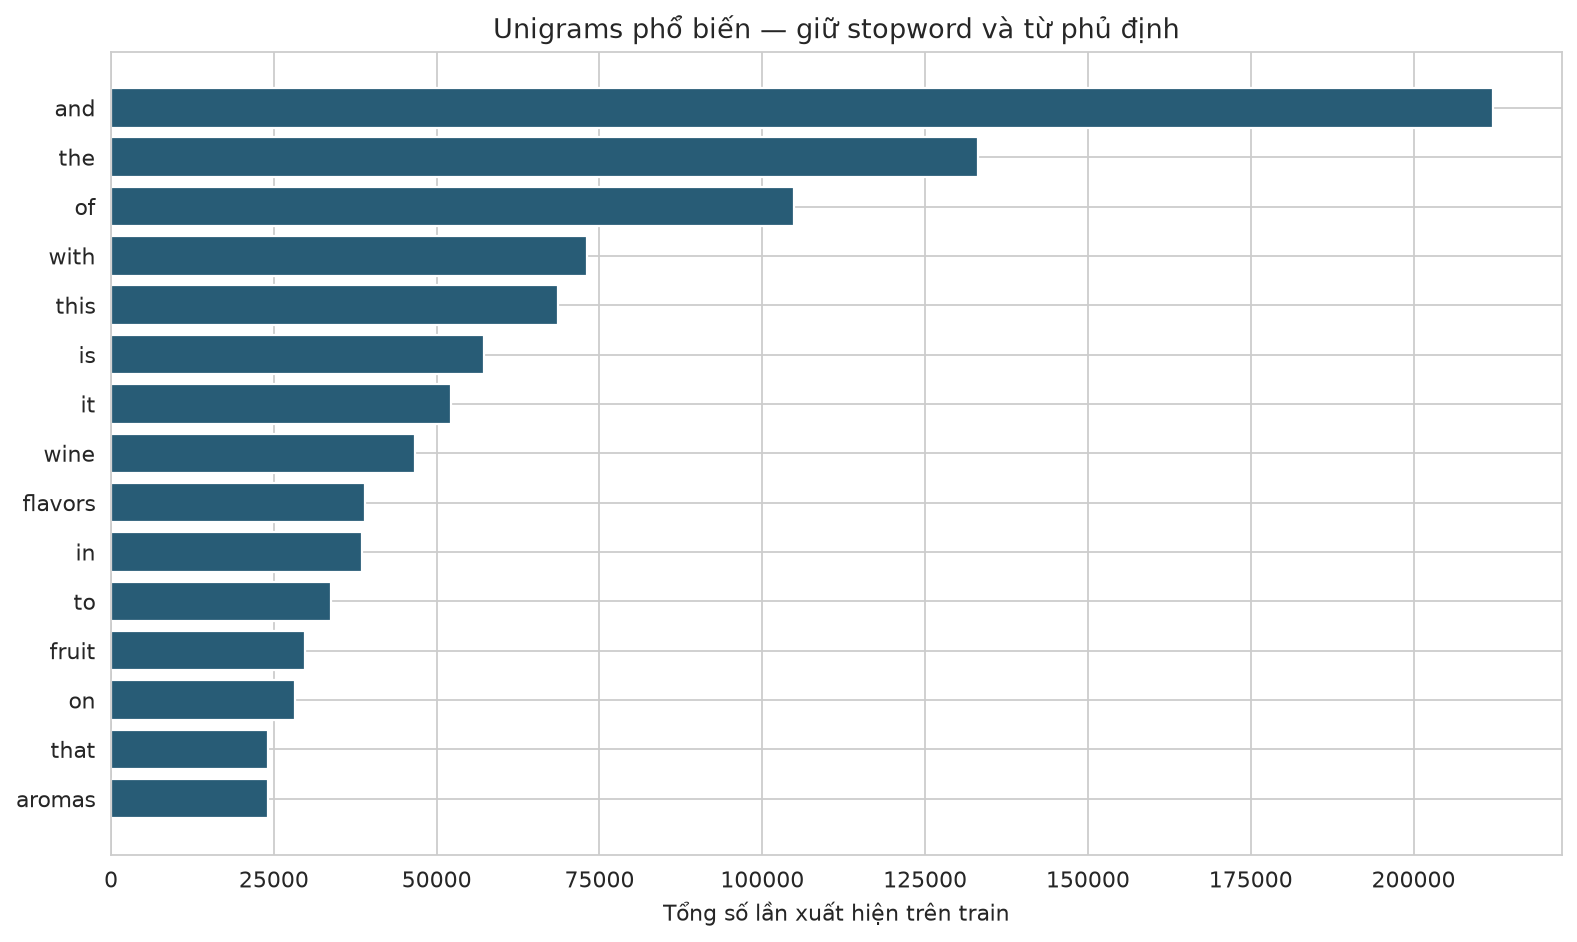

,term,occurrences,documents
0,on the,20518,17461
1,the palate,14614,14427
2,this is,14586,14056
3,aromas of,10851,10833
4,the finish,10604,10582
5,this wine,10412,10218
6,in the,9763,9175
7,flavors of,9752,9674
8,the wine,9187,8694
9,the nose,8169,8093


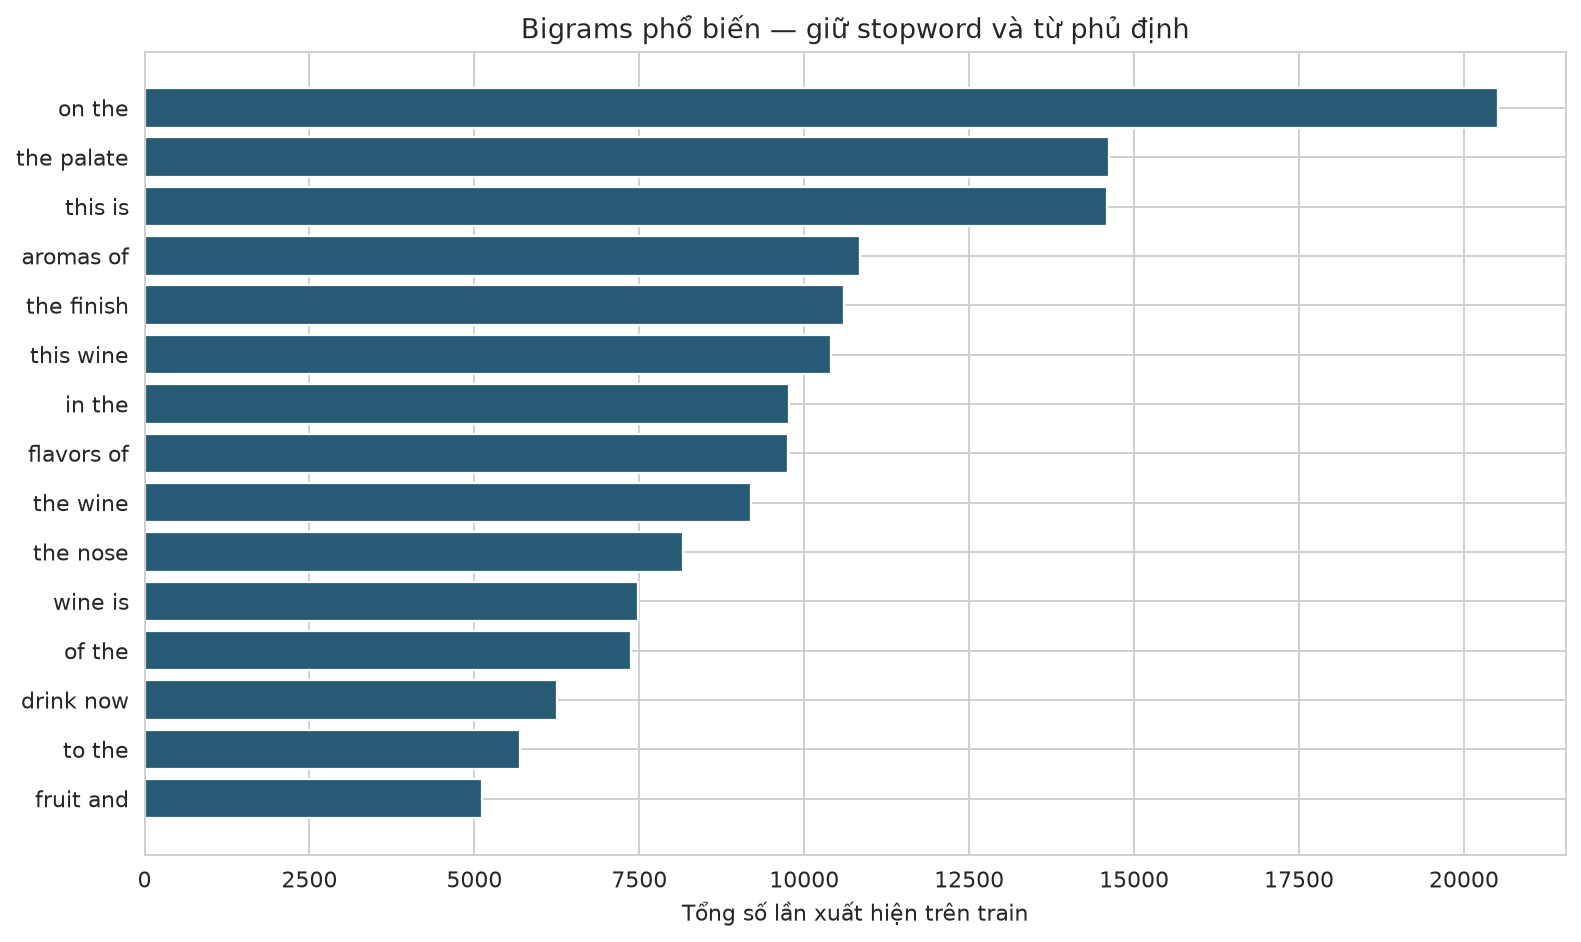

,term,occurrences,documents
0,wine,46615,37783
1,flavors,38951,37020
2,fruit,29773,26544
3,aromas,24058,23760
4,palate,23599,23124
5,finish,21744,21575
6,acidity,20202,19727
7,drink,17914,17688
8,tannins,18108,17613
9,cherry,17954,16776


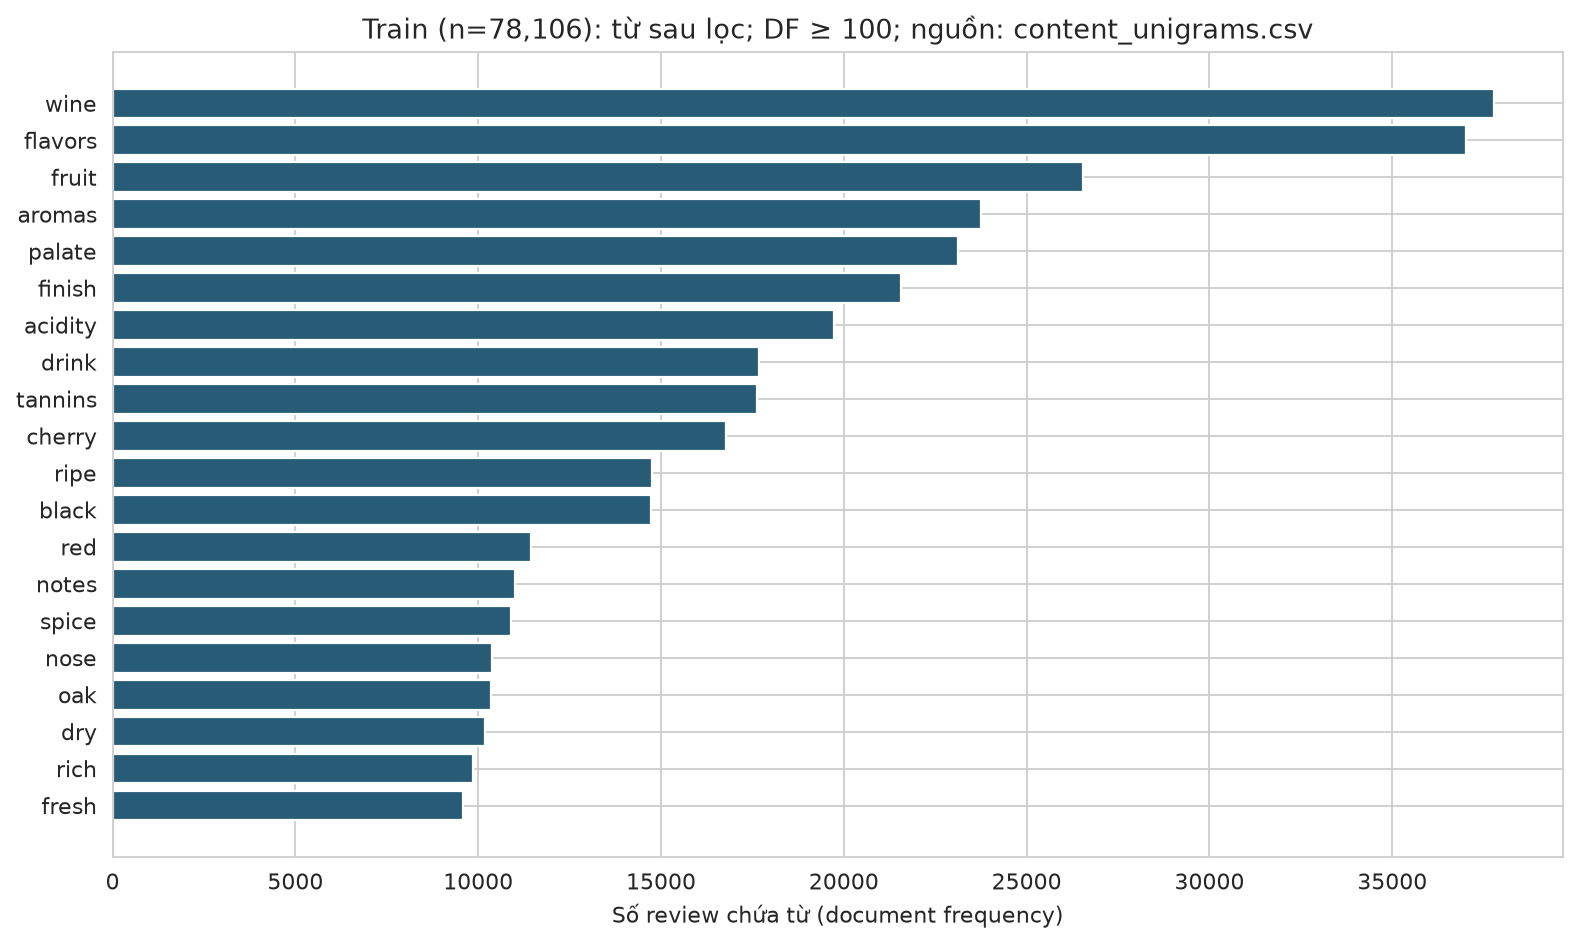

**Kết quả:** trung vị 40 từ; 29 review dưới 10 từ. Bảng lọc bổ sung giúp đọc từ vựng; tần suất không đo ảnh hưởng lên điểm.

In [5]:
display(tables['review_summary'])
show_figure('05_review_length')
display(tables['review_length_groups'])
show_figure('10_review_length_by_points')
for kind in ['unigrams', 'bigrams']:
    display(tables[kind])
    show_figure(f'06_{kind}')
display(tables['content_unigrams'])
show_figure('09_content_unigrams')
r = tables['review_summary'].iloc[0]
display(Markdown(f"**Kết quả:** trung vị {r.median_words:g} từ; {int(r.under_10_words)} review dưới 10 từ. Bảng lọc bổ sung giúp đọc từ vựng; tần suất không đo ảnh hưởng lên điểm."))

## 5. Thống kê giá–điểm ở cấp nhóm title
Đây là phân tích khám phá sau EDA, không phải giả thuyết đăng ký trước. Mỗi nhóm title đóng góp trung vị giá và điểm; Spearman hai phía, p-value xấp xỉ; CI percentile 95% từ 2.000 bootstrap nhóm, seed 42. Không kiểm định riêng log giá vì giữ cùng thứ hạng. Các nhóm có thể còn phụ thuộc qua winery/người chấm; chưa kiểm soát nhiễu hoặc chứng minh nhân quả.

In [6]:
association_dir = ROOT / 'outputs/analysis'
if not (association_dir / 'summary.json').is_file():
    raise FileNotFoundError('Chạy python -m src.analyze_associations trước notebook này')
association_info = json.loads((association_dir / 'summary.json').read_text(encoding='utf-8'))
train_path = ROOT / 'data/processed/splits/train.csv'
assert association_info['inputs'][str(train_path.resolve())] == sha256(train_path)
display(pd.read_csv(association_dir / 'price_points_spearman.csv'))
a = association_info['result']
if a['status'] == 'ok':
    display(Markdown(f"**Kết quả:** {a['groups']:,} nhóm; rho={a['rho']:.4f}; CI95% [{a['ci_low']:.4f}, {a['ci_high']:.4f}]. P-value bằng 0 trong máy nếu underflow không phải xác suất đúng bằng 0. Ý nghĩa thống kê không thay thế độ lớn hệ số."))
else:
    display(Markdown('Không đủ điều kiện để kết luận.'))

,groups,bootstrap_repetitions,seed,status,rho,p_value_approx,ci_low,ci_high,valid_bootstrap
0,77437,2000,42,ok,0.615765,0.0,0.611021,0.620216,2000


**Kết quả:** 77,437 nhóm; rho=0.6158; CI95% [0.6110, 0.6202]. P-value bằng 0 trong máy nếu underflow không phải xác suất đúng bằng 0. Ý nghĩa thống kê không thay thế độ lớn hệ số.

## 6. Trùng review và giới hạn đánh giá
Audit chỉ nhận diện chuỗi sau lowercase/trim/gộp khoảng trắng. Giữ split và mọi dòng; mô hình đã báo kết quả tổng thể và metric phụ loại review trùng train. Không phát hiện near-duplicate, không khẳng định zero leakage. Holdout seed 42 từng được quan sát.

In [7]:
display(tables['review_overlap'])

,left,right,shared_unique_reviews
0,train,val,6
1,train,test,5
2,val,test,1


## 7. Mô hình trả lời được gì và chưa trả lời được gì?
Mô hình kết hợp đã đánh giá; notebook này chỉ dẫn đến báo cáo, không tính lại hoặc tuning.

- [Báo cáo đánh giá bổ sung](../outputs/model_report/REPORT.md): baseline, sai số theo ngưỡng, nhóm điểm và trường hợp validation.
- [Báo cáo test gốc](../docs/model_test_report.md): MAE/RMSE/R² và lịch sử holdout.
- [Minh họa đặc trưng](../outputs/feature_examples/REPORT.md): encoder đã lưu, không fit lại.
- [Báo cáo EDA đầy đủ](../outputs/eda/REPORT.md): số liệu tự sinh từ cùng bảng CSV.

**Kết luận:** giá và metadata có những liên hệ mô tả với điểm; review là lời của người chấm. Chưa có đối chứng metadata-only để kết luận lợi ích riêng của review. Mô hình cần review đã tồn tại, không dự đoán chất lượng khách quan trước khi có review. Mọi hình/bảng được tạo lại bằng code; không sửa tay số liệu.